# Exercice 3 - Remplacez la Q-table par un cerveau neuronal (DQN)

Une Q-table a besoin d'une ligne par situation. Sur `CartPole-v1` une observation est faite de 4 nombres à virgule, donc d'une infinité de situations, et la table n'existe pas.

Le Deep Q-Network remplace la table par un réseau de neurones : on lui présente l'observation, il renvoie une note par action. C'est ce que contenait une ligne de la table.

Deux implémentations ici :

1. à la main avec PyTorch, avec le réseau, le replay buffer et le réseau cible
2. avec Stable-Baselines3

In [1]:
# Installation des librairies
%pip install -q gymnasium stable-baselines3 torch matplotlib tensorboard

Note: you may need to restart the kernel to use updated packages.


C:\Users\gregh\Desktop\OpenClassrooms\AI Engineer\P11\.venv\Scripts\python.exe: No module named pip


In [2]:
import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

print("Version de PyTorch   :", torch.__version__)
print("Version de Gymnasium :", gym.__version__)

Version de PyTorch   : 2.14.0+cpu
Version de Gymnasium : 1.3.0


## Étape 1 : le réseau de neurones et le replay buffer

`DQN` hérite de `torch.nn.Module`. Les couches `nn.Linear` sont déclarées dans `__init__`, `forward` les enchaîne avec `F.relu` entre chacune. Entrée : une observation. Sortie : une valeur par action.

`ReplayBuffer` garde les transitions passées. L'entraînement ne porte pas sur la dernière transition vécue mais sur un lot tiré au hasard dans la mémoire. Deux transitions qui se suivent dans un épisode sont presque identiques, apprendre dessus en série déstabilise le réseau.

`collections.deque(maxlen=...)` gère la capacité fixe : au-delà, les transitions les plus anciennes sont évacuées automatiquement.

In [3]:
class DQN(nn.Module):
    """Remplace la Q-table : estime une note pour chaque action."""

    def __init__(self, n_observations, n_actions):
        super().__init__()
        self.layer1 = nn.Linear(n_observations, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, n_actions)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)

In [4]:
class ReplayBuffer:
    """Memoire des transitions, avec tirage aleatoire par lots."""

    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [5]:
env = gym.make("CartPole-v1")
n_observations = env.observation_space.shape[0]
n_actions = env.action_space.n

print("Entrées du réseau (taille d'une observation) :", n_observations)
print("Sorties du réseau (nombre d'actions)         :", n_actions)
print()

reseau = DQN(n_observations, n_actions)
print(reseau)
print()
print("Nombre de paramètres à apprendre :", sum(p.numel() for p in reseau.parameters()))

Entrées du réseau (taille d'une observation) : 4
Sorties du réseau (nombre d'actions)         : 2

DQN(
  (layer1): Linear(in_features=4, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=2, bias=True)
)

Nombre de paramètres à apprendre : 17410


## Étape 2 : la boucle d'entraînement

### Les deux réseaux

`policy_net` joue et apprend. `target_net` est une copie, utilisée uniquement pour calculer la valeur cible.

Avec un seul réseau, la cible se déplacerait à chaque correction puisqu'elle serait produite par le réseau en cours de modification. La copie reste donc figée, et n'est remise à jour que tous les `TARGET_UPDATE` épisodes.

### Ce que fait chaque bloc

**Sélection de l'action.** Tirage entre 0 et 1. En dessous d'`epsilon`, action au hasard. Sinon, l'action la mieux notée par `policy_net`. `epsilon` décroît à chaque épisode.

**Valeurs Q.** `policy_net(states)` renvoie une note par action. Seule celle de l'action réellement jouée est conservée, par `.gather(1, actions)`.

**Valeur cible.** `target_net(next_states).max(1)[0]` donne la meilleure note atteignable depuis l'état suivant. La cible vaut `reward + gamma * cette valeur`. Quand l'épisode s'est terminé il n'y a pas de suite, et le `* (1 - dones)` annule ce terme.

**Perte.** Erreur quadratique moyenne entre la prédiction et la cible.

**Optimisation.** `zero_grad()`, `backward()`, `step()`.

### Tenseurs

Les transitions sortent du buffer en listes Python. `torch.FloatTensor` pour les observations et les récompenses, `torch.LongTensor` pour les actions, qui sont des indices de colonne et que `gather` exige entiers. `.unsqueeze(1)` fait passer les actions d'une ligne à une colonne, la forme attendue par `gather`.

In [6]:
# Seeds fixées : sinon le résultat varie beaucoup d'une exécution à l'autre.
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
env.action_space.seed(SEED)
env.reset(seed=SEED)

# Hyperparamètres
N_EPISODES = 400
BATCH_SIZE = 64
GAMMA = 0.99
LR = 1e-3
TAILLE_BUFFER = 10000
TARGET_UPDATE = 10        # on recopie les poids tous les 10 épisodes

EPSILON_DEPART = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.995

# Le réseau qui apprend, et sa copie figée
policy_net = DQN(n_observations, n_actions)
target_net = DQN(n_observations, n_actions)
target_net.load_state_dict(policy_net.state_dict())

optimizer = torch.optim.Adam(policy_net.parameters(), lr=LR)
memory = ReplayBuffer(TAILLE_BUFFER)

In [7]:
def optimize_model():
    """Un pas de descente de gradient sur un lot tire dans le buffer."""

    # Pas encore assez de transitions pour un lot complet
    if len(memory) < BATCH_SIZE:
        return

    lot = memory.sample(BATCH_SIZE)
    states, actions, rewards, next_states, dones = zip(*lot)

    # LongTensor pour les actions : ce sont des indices
    states = torch.FloatTensor(np.array(states))
    actions = torch.LongTensor(actions).unsqueeze(1)
    rewards = torch.FloatTensor(rewards)
    next_states = torch.FloatTensor(np.array(next_states))
    dones = torch.FloatTensor(dones)

    # Prediction du policy_net pour les actions reellement jouees
    q_values = policy_net(states).gather(1, actions).squeeze(1)

    # Cible : meilleure valeur atteignable depuis l'etat suivant, vue par le target_net
    with torch.no_grad():
        max_q_futur = target_net(next_states).max(1)[0]
    q_cibles = rewards + GAMMA * max_q_futur * (1 - dones)

    loss = F.mse_loss(q_values, q_cibles)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [8]:
epsilon = EPSILON_DEPART
recompenses = []

for episode in range(N_EPISODES):

    state, info = env.reset()
    total_reward = 0.0
    terminated = False
    truncated = False

    while not terminated and not truncated:

        # Exploration, ou action la mieux notée par policy_net
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                action = int(policy_net(torch.FloatTensor(state)).argmax())

        next_state, reward, terminated, truncated, info = env.step(action)

        # Mémorisation de la transition, puis apprentissage sur un lot du buffer
        memory.push(state, action, reward, next_state, float(terminated))
        state = next_state
        total_reward += reward
        optimize_model()

    recompenses.append(total_reward)
    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)

    # Mise à jour périodique du réseau cible
    if (episode + 1) % TARGET_UPDATE == 0:
        target_net.load_state_dict(policy_net.state_dict())

    if (episode + 1) % 50 == 0:
        moyenne = np.mean(recompenses[-50:])
        print(f"Épisode {episode + 1:3d} | moyenne des 50 derniers : {moyenne:6.1f} | epsilon = {epsilon:.3f}")

env.close()

Épisode  50 | moyenne des 50 derniers :   26.7 | epsilon = 0.778
Épisode 100 | moyenne des 50 derniers :   52.7 | epsilon = 0.606
Épisode 150 | moyenne des 50 derniers :   68.3 | epsilon = 0.471
Épisode 200 | moyenne des 50 derniers :   66.6 | epsilon = 0.367
Épisode 250 | moyenne des 50 derniers :   80.8 | epsilon = 0.286
Épisode 300 | moyenne des 50 derniers :   75.8 | epsilon = 0.222
Épisode 350 | moyenne des 50 derniers :   86.6 | epsilon = 0.173
Épisode 400 | moyenne des 50 derniers :  289.4 | epsilon = 0.135


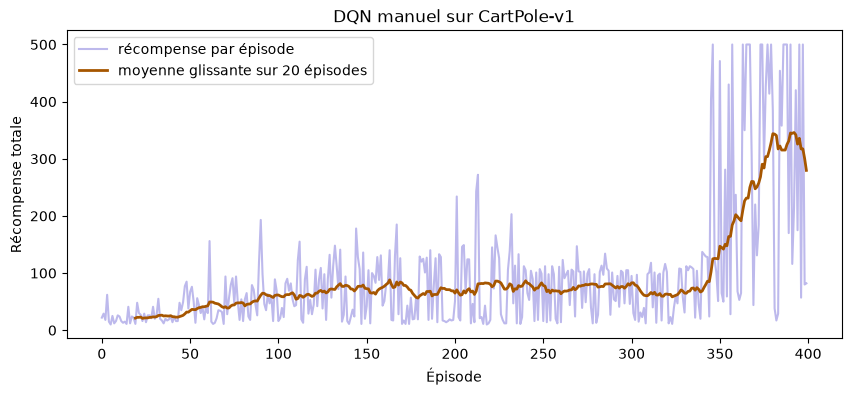

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(recompenses, alpha=0.35, color="#4338CA", label="récompense par épisode")

# Moyenne glissante : la courbe brute est trop bruitée pour lire une tendance
fenetre = 20
moyenne_glissante = np.convolve(recompenses, np.ones(fenetre) / fenetre, mode="valid")
plt.plot(range(fenetre - 1, len(recompenses)), moyenne_glissante,
         color="#A65600", linewidth=2, label=f"moyenne glissante sur {fenetre} épisodes")

plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.title("DQN manuel sur CartPole-v1")
plt.legend()
plt.show()

Les moyennes affichées tous les 50 épisodes partent d'une vingtaine de steps et finissent plusieurs fois plus haut.

La courbe brute est très bruitée : des épisodes à 500 voisinent avec des épisodes à 30. Un petit changement de poids suffit à faire basculer une décision.

## Étape 3 : le même algorithme avec Stable-Baselines3

La classe `DQN` de SB3 contient déjà le réseau, le replay buffer, le réseau cible et la boucle d'entraînement.

### Hyperparamètres

Les valeurs par défaut de SB3 sont calibrées pour Atari et ne conviennent pas à CartPole. `target_update_interval` y vaut 10 000, donc sur 25 000 steps le réseau cible ne serait recopié que deux fois, et `learning_rate` vaut 1e-4, trop faible ici.

Les valeurs utilisées ci-dessous sont celles publiées par le RL Zoo pour `CartPole-v1`, avec les 50 000 steps prévus par cette configuration.

### Deux détails d'implémentation

La classe `DQN` de SB3 porte le même nom que celle définie plus haut (donc alias `DQN_SB3` à l'import).

L'environnement est enveloppé dans un `Monitor`, ce que SB3 demande pour l'évaluation (il enregistre la longueur et la récompense réelles de chaque épisode).

In [10]:
from stable_baselines3 import DQN as DQN_SB3
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

env = Monitor(gym.make("CartPole-v1"))

# Hyperparamètres publiés par le RL Zoo pour CartPole-v1
model = DQN_SB3(
    "MlpPolicy",
    env,
    verbose=1,
    tensorboard_log="./logs/",
    seed=SEED,
    learning_rate=2.3e-3,
    batch_size=64,
    buffer_size=100000,
    learning_starts=1000,
    gamma=0.99,
    target_update_interval=10,
    train_freq=256,
    gradient_steps=128,
    exploration_fraction=0.16,
    exploration_final_eps=0.04,
    policy_kwargs=dict(net_arch=[256, 256]),
)

model.learn(total_timesteps=50000, log_interval=50)

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./logs/DQN_2
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 22.1     |
|    ep_rew_mean      | 22.1     |
|    exploration_rate | 0.867    |
| time/               |          |
|    episodes         | 50       |
|    fps              | 4600     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1105     |
| train/              |          |
|    learning_rate    | 0.0023   |
|    loss             | 0.0154   |
|    n_updates        | 128      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30.4     |
|    ep_rew_mean      | 30.4     |
|    exploration_rate | 0.635    |
| time/               |          |
|    episodes         | 100      |
|    fps              | 1582     |
|    time_elapsed     | 1        |
|    total_timesteps  | 3041     |
| train/              |          |
|    learning_

In [11]:
mean_reward, std_reward = evaluate_policy(model, env, n_eval_episodes=100)
print(f"Récompense moyenne sur 100 épisodes : {mean_reward:.1f} +/- {std_reward:.1f}")

model.save("dqn_cartpole")
print("Modèle sauvegardé dans dqn_cartpole.zip")

env.close()

Récompense moyenne sur 100 épisodes : 500.0 +/- 0.0
Modèle sauvegardé dans dqn_cartpole.zip


## Résultats

Le modèle SB3 fait nettement mieux que la version manuelle, et tient son score sur les 100 épisodes d'évaluation.

L'écart ne vient pas du code (les deux versions implémentent le même algorithme, avec le même réseau, le même replay buffer et le même réseau cible), il vient des hyperparamètres : ceux du RL Zoo ont été cherchés par essais successifs sur cet environnement précis, ceux de la version manuelle sont choisis à la main.

L'apport d'une bibliothèque comme SB3 fait donc deux choses : du code déjà écrit et débogué, et des jeux d'hyperparamètres publiés pour les environnements courants.

### Sur la stabilité

Le DQN reste instable même avec ces hyperparamètres. Sans seed fixe, la récompense moyenne finale varie fortement d'une exécution à l'autre : sur six essais, trois atteignent 500 et les autres tombent entre 126 et 400. D'où les seeds fixées ici, et d'où l'usage en apprentissage par renforcement de rapporter des moyennes sur plusieurs seeds plutôt qu'un chiffre unique.